# CS 839 HW1: Agent memory experiment (no memory, episodic, structured)

Runs the 12 tasks in `data/tasks.json` **in order** (T1 → T12) under three memory conditions and compares them.

- **No memory**: every task starts from scratch. Same requests as `hw1_no_memory.ipynb`.
- **Episodic**: after each task the episode (request, tool calls, answer, verdict) is stored; the 3 most similar past episodes are shown with the next request.
- **Structured**: after each task an LLM writer updates a compact list of rules, procedures, warnings and exceptions (at most 8 records, 150 words), which is shown with every request.

**Feedback is binary.** After each task the memory learns only whether the answer was judged CORRECT or INCORRECT, like a colleague saying "these numbers don't check out". It never sees the reference answer, the grader's failure label, `failure_conditions` or `reference_calls`.

Protocol (from the README): one run = T1 to T12 in order; memory is cleared at the start of each run; 5 runs per condition; conditions interleaved; no memory re-run alongside. Same model (`gpt-5.6-luna`) and tools in every condition, and the memory writer uses the same model.

Code: `utils/agent.py` (the agent loop from `hw1_no_memory.ipynb` plus a memory hook), `utils/memory.py` (the three conditions), `utils/experiment.py` (runs and saved traces), `utils/test_memory.py` (offline checks). Run this notebook from the repo root.

## 1. Setup

The API key is read from a `.env` file in this folder or any parent folder (`OPENAI_API_KEY`, optional `CS839_MODEL`). Otherwise it is entered with `getpass`. Never paste a key into a code cell or commit `.env`.

In [1]:
%pip install -q -r requirements.txt matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from utils.agent import compact_trace
from utils.experiment import CONDITIONS, load_env, load_spec, load_traces, make_client, run_all, spent_usd, trace_cost
from utils.grader import grade_canonical
from utils.memory import EPISODIC_HEADER, STRUCTURED_HEADER, WRITER_INSTRUCTIONS, render_records

env_found = load_env() is not None
MODEL = os.getenv("CS839_MODEL", "gpt-5.6-luna")
if not os.getenv("OPENAI_API_KEY"):
    import getpass
    entered_key = getpass.getpass("Paste your team's API key (hidden): ").strip()
    if entered_key:
        os.environ["OPENAI_API_KEY"] = entered_key

client = make_client() if os.getenv("OPENAI_API_KEY") else None
print(f"Model: {MODEL} | .env {'found' if env_found else 'not found'}")
print("API client ready." if client else "No key supplied. Saved runs can still be analyzed.")

Model: gpt-5.6-luna | .env found
API client ready.


## 2. Hypotheses (written and committed before any memory-condition run)

Baseline: no memory, 5 runs on Oct 6 (`runs/no_memory_20261006_121523.json`): T1 5/5, T2 3/5, T3 5/5, T4 5/5, T5 0/5, T6 0/5, T7 1/5, T8 5/5, T9 1/5, T10 5/5, T11 4/5, T12 2/5. Almost every miss comes from the default projection EPSG:3857.

**H1 (memory helps).** Structured memory will fix the area and density tasks that come after T2. T5, T6, T7 and T12 will each go from at most 2/5 without memory to at least 4/5, because after T2 the writer will store a rule to use `projection="EPSG:5070"` for area and density. Episodic memory will help less, at most 3/5 on average over T5–T7, because the agent must retrieve the T2 episode and re-derive the rule from a raw trace.

**H2 (memory hurts or has no effect).** Memory will not help on the two exceptions, and can hurt:
- T9 (Alaska–Maine distance): in at least 2 of 5 runs of each memory condition the agent will carry the area rule over to distance and use planar EPSG:5070 (5,801 km instead of the geodesic 5,350.4 km), so neither memory condition will beat no memory on T9 by more than one run.
- T8 (U.S. total): in at least 1 of 5 runs of a memory condition, the "states means the 50 states" lesson from T4–T7 will make the agent leave out DC (341,091,212), while no memory gets 5/5.
- T1, T3, T4, T10 (5/5 without memory): memory will not change accuracy; it will only add input tokens.

## 3. Tasks

`data/tasks.json` is the source of truth (questions, answer formats, reference answers, known mistakes). The order is T1 → T12.

In [3]:
SPEC = load_spec()
TASKS = {t["id"]: t for t in SPEC["tasks"]}
ORDER = [t["id"] for t in SPEC["tasks"]]

pd.set_option("display.max_colwidth", 140)
pd.DataFrame([{"id": t["id"], "type": t["type"], "rules": ", ".join(t["rules"]), "question": t["question"]}
              for t in SPEC["tasks"]]).set_index("id")

,type,rules,question
id,,,
T1,warm-up,,"Our annual report opens with the most populous state. Which state is it, and what was its population in 2025?"
T2,learn,B,A draft slide says the most populous state is also the largest state by area. Is that right? Give the area in km² of both states.
T3,warm-up,,For the Wisconsin state brief: how many states had more people than Wisconsin in 2025?
T4,learn,A,A federal pilot program is open only to states with fewer people than Wisconsin in 2025. How many states are eligible?
T5,reuse,B,A rural health program targets the 5 least densely populated states. List them with their densities in people per km².
T6,reuse,"A, B",A small-states grant covers the 5 states with the smallest area. List them with their areas in km².
T7,reuse,"A, B",A transit funding memo needs the 5 most densely populated states. List them with their densities in people per km².
T8,exception,A (exception),The report's headline figure is the population of the United States in the Census Bureau's 2025 estimates. What is it?
T9,exception,B (exception),A map caption needs the distance in km between the centroids of Alaska and Maine. What is it?


## 4. The memory conditions

| | Episodic | Structured |
|---|---|---|
| **Write** | After each task, store the episode as text: request, every tool call with its arguments and a truncated result, the final answer, and the verdict. No LLM call. | After each task, one writer call (same model) sees the current memory, the episode text, the verdict and the tool descriptions, and returns the full updated memory plus a change log. |
| **Retrieve** | Before each task, TF-IDF cosine (character 4-grams) between the new request and each stored episode; the top 3 are shown. Ties go to the most recent. | The whole memory is shown with every request (it is small). |
| **Update** | None: episodes are never edited. | The writer adds, revises, merges or deletes records. On a conflict it should narrow the old record and add an `exception`. |
| **Forget** | None within a run (at most 11 episodes). | Hard budget of 8 records and 150 words: one re-prompt if over budget, then the least supported records (fewest evidence entries) are cut. In the saved runs every over-budget reply was fixed by the re-prompt. |

Both memories are cleared at the start of each run. The exact text shown to the agent at each task is saved in the trace (`memory_shown`), and so is the memory after each update (`memory_after`).

In [4]:
print(EPISODIC_HEADER, "\n")
print(STRUCTURED_HEADER, "\n")
print("WRITER INSTRUCTIONS\n" + WRITER_INSTRUCTIONS.format(max_records=8, max_words=150))

PAST EPISODES: your own earlier attempts at related requests, each with the reviewer's verdict (CORRECT or INCORRECT; the reviewer gave no other feedback). They may or may not apply to the current request. 

MEMORY: lessons you recorded after earlier requests, based on whether a reviewer judged each answer CORRECT or INCORRECT. Apply a lesson only when its 'when' condition matches the current request. 

WRITER INSTRUCTIONS
You maintain the long-term memory of an analyst agent. The agent answers a sequence of short, different data requests using a fixed set of tools. After each request you see what the agent did and whether a reviewer judged the final answer CORRECT or INCORRECT. The reviewer gives no other feedback and never reveals the right answer.

Update the memory so that the agent does better on future, different requests.

Each memory record has:
- id: a short unique string such as "m1"
- type: "rule", "procedure", "warning" or "exception"
- when: the kind of request or tool use

## 5. Offline checks (no API credit)

The grader must pass every reference answer and label every known mistake, and `utils/test_memory.py` checks the memory code with a stub client, including that no forbidden field ever reaches the agent or the writer.

In [5]:
for t in SPEC["tasks"]:
    assert grade_canonical(t, t["answer"])["correct"], t["id"]
    for fc in t["failure_conditions"]:
        g = grade_canonical(t, fc["answer"])
        assert not g["correct"] and g["label"] == fc["cause"], (t["id"], g)
print("Grader OK on all 12 reference answers and",
      sum(len(t["failure_conditions"]) for t in SPEC["tasks"]), "known mistakes.\n")

out = subprocess.run([sys.executable, "utils/test_memory.py"], capture_output=True, text=True)
print(out.stdout[-2500:] or out.stderr[-2500:])

Grader OK on all 12 reference answers and 16 known mistakes.



ok   names: 'all' kept as is
ok   names: 50 states listed by what was left out
ok   names: short lists written out
ok   names: repeated names reported
ok   names: unknown names reported
ok   compact trace survives malformed tool arguments
ok   compact trace shows the projection argument
ok   compact trace: no step limit message when answered
ok   no memory: instructions identical to hw1_no_memory.ipynb
ok   no memory: user prompt is question + answer format
ok   stub task graded correct
ok   memory text appended after the instructions
     retrieved episodes: T1<--, T2<-T1, T3<-T1/T2, T4<-T3/T1/T2, T5<-T4/T3/T1, T6<-T2/T5/T4, T7<-T5/T1/T3, T8<-T1/T3/T4, T9<-T2/T7/T5, T10<-T4/T3/T7, T11<-T3/T4/T8, T12<-T7/T3/T4
ok   episodic: nothing to retrieve for T1
ok   episodic: at most k episodes, only earlier tasks
ok   episodic: T7 (most dense) retrieves T5 (least dense)
ok   episodic: T6 (smallest area) retrieves T2 (area)
ok   episodic: T12 (density) retrieves a density task
ok   episodic: T10

## 6. Helpers for reading traces

In [6]:
def show_trace(t, result_chars=200):
    verdict = "CORRECT" if t["correct"] else f"WRONG ({t['label']})"
    print(f"=== {t['condition']} | run {t['run']} | {t['task']} | {verdict} ===")
    if t.get("memory_shown"):
        print("Memory shown to the agent:")
        print("\n".join("  | " + line for line in t["memory_shown"].splitlines()))
    else:
        print("Memory shown to the agent: (none)")
    print(compact_trace(t["question"], t["calls"], t["final_answer"], result_chars))
    changes = (t.get("memory_update") or {}).get("changes") or []
    if changes:
        print("Memory changes after this task:")
        for c in changes:
            print("  -", c)
    print(f"tool calls {t['tool_calls']}, model calls {t['model_calls']}, "
          f"tokens in {t['input_tokens']:,}, out {t['output_tokens']:,}\n")


def sequence(traces, condition, run):
    return sorted((t for t in traces if t["condition"] == condition and t["run"] == run),
                  key=lambda t: ORDER.index(t["task"]))


def show_memory_timeline(traces, condition, run):
    for t in sequence(traces, condition, run):
        mark = "right" if t["correct"] else "WRONG"
        if condition == "structured":
            print(f"--- after {t['task']} ({mark}) ---")
            print(render_records(t["memory_after"]) or "(empty)")
            for c in t["memory_update"].get("changes", []):
                print("    change:", c)
        else:
            stored = ", ".join(f"{e['task']}:{'right' if e['correct'] else 'wrong'}" for e in t["memory_after"])
            print(f"{t['task']} ({mark}) | shown before this task: {t['retrieved'] or '-'} | stored after: {stored}")

## 7. Smoke test: T1–T4 with each memory

A cheap end-to-end check (two short sequences) before the full experiment: are the episodes and the writer's JSON sensible?

In [7]:
SMOKE_DIR = Path("runs/memory_smoke")
MAIN_DIR = Path("runs/memory_main")
BUDGET_USD = 3.00                      # the course limit is $5 per team; stop well before it
BUDGET_DIRS = (SMOKE_DIR, MAIN_DIR)

if client is not None:
    run_all(client, MODEL, SPEC, SMOKE_DIR, runs=[1], conditions=("episodic", "structured"),
            task_ids=["T1", "T2", "T3", "T4"], workers=2, budget_usd=BUDGET_USD, budget_dirs=BUDGET_DIRS)
smoke = load_traces(SMOKE_DIR)
for condition in ("episodic", "structured"):
    print(f"\n########## {condition} ##########")
    show_memory_timeline(smoke, condition, 1)

0 sequences to run in runs/memory_smoke (2 already saved)
done; spent so far $0.8642

########## episodic ##########
T1 (right) | shown before this task: - | stored after: T1:right
T2 (WRONG) | shown before this task: ['T1'] | stored after: T1:right, T2:wrong
T3 (right) | shown before this task: ['T1', 'T2'] | stored after: T1:right, T2:wrong, T3:right
T4 (right) | shown before this task: ['T3', 'T1', 'T2'] | stored after: T1:right, T2:wrong, T3:right, T4:right

########## structured ##########
--- after T1 (right) ---
- [m1 | procedure] When: Requests for the most populous region or state Do: Use get_population with names="all", order="desc", limit=1; report the first row's name and population, verifying it is a state when the request specifically says state. (evidence: T1:right)
    change: added m1: use descending population order to identify the most populous state or region
--- after T2 (WRONG) ---
- [m1 | procedure] When: Requests asking for the most populous state Do: Use list_r

## 8. Full experiment: 5 runs × 3 conditions

Each (condition, run) is saved to `runs/memory_main/<condition>_runNN.json` as soon as it finishes, so re-running this cell resumes and never repeats a finished sequence. Sequences are queued run by run (run 1 of all three conditions, then run 2, …), so the conditions are interleaved in time.

The saved runs were made on Oct 11, 2026 from the command line, with `utils/` as of commit `4aafee0`: `python -m utils.experiment --out runs/memory_main --runs 1-5 --workers 6`, then the same with `--runs 6-10` (two runs, six sequences, at a time). The cells below run the same function with the same settings; with everything saved they only report "0 sequences to run".

Later commits fix edge cases found in review, none of which changed what any agent saw: a tool call with a repeated name was summarized inaccurately (7 of the 868 calls, all in T12, the last task, so only the writer's final update in four structured runs saw it); malformed tool arguments could crash the memory update (never occurred: no sequence failed); a writer-retry path and the budget truncation never occurred; and the budget guard and resume logic were tightened. Grading is unaffected.

In [8]:
N_RUNS = 5
if client is not None:
    run_all(client, MODEL, SPEC, MAIN_DIR, runs=range(1, N_RUNS + 1), workers=6,
            budget_usd=BUDGET_USD, budget_dirs=BUDGET_DIRS)
print(f"Spent on the memory experiment so far: ${spent_usd(*BUDGET_DIRS):.3f}")

0 sequences to run in runs/memory_main (15 already saved)
done; spent so far $0.8642
Spent on the memory experiment so far: $0.864


## 9. Stability reruns

After runs 1–5, three comparisons were close or surprising: (1) no memory solved T5 in 4/5 runs, against 0/5 on Oct 6 with identical prompts and questions; (2) both memory conditions went 0/5 on T5; (3) structured memory beat no memory on T7 (2/5 vs 0/5) and T12 (2/5 vs 0/5). All three conditions were therefore run 5 more times (runs 6–10) with the same code and protocol. Every one of these comparisons kept its direction in runs 6–10 (T5: none 2/5, episodic 0/5, structured 0/5; T7: 0/5, 0/5, 3/5; T12: 2/5, 0/5, 4/5), although none of them is significant within runs 6–10 alone (see the batch table in section 10). The results below pool all 10 runs.

In [9]:
STABILITY_RUNS = range(6, 11)
STABILITY_CONDITIONS = CONDITIONS
if client is not None:
    run_all(client, MODEL, SPEC, MAIN_DIR, runs=STABILITY_RUNS, conditions=STABILITY_CONDITIONS, workers=6,
            budget_usd=BUDGET_USD, budget_dirs=BUDGET_DIRS)
print(f"Spent on the memory experiment so far: ${spent_usd(*BUDGET_DIRS):.3f}")

0 sequences to run in runs/memory_main (15 already saved)
done; spent so far $0.8642
Spent on the memory experiment so far: $0.864


## 10. Results

In [10]:
traces = load_traces(MAIN_DIR)
baseline = json.loads(Path("runs/no_memory_20261006_121523.json").read_text())
for t in baseline:
    t["condition"] = "none (Oct 6)"


def row(t):
    upd = t.get("memory_update") or {}
    return {"condition": t["condition"], "run": t["run"], "task": t["task"], "correct": t["correct"],
            "label": t["label"], "tool_calls": t["tool_calls"], "model_calls": t["model_calls"],
            "input_tokens": t["input_tokens"], "output_tokens": t["output_tokens"],
            "memory_calls": upd.get("memory_calls", 0), "memory_input_tokens": upd.get("memory_input_tokens", 0),
            "memory_output_tokens": upd.get("memory_output_tokens", 0), "cost_usd": trace_cost(t)}


df = pd.DataFrame([row(t) for t in traces])
df_all = pd.concat([df, pd.DataFrame([row(t) for t in baseline])], ignore_index=True)
COLS = ["none (Oct 6)", *CONDITIONS]

counts = df_all.groupby(["task", "condition"])["correct"].agg(["sum", "count"])
table = (counts["sum"].astype(int).astype(str) + "/" + counts["count"].astype(str)).unstack()[COLS].reindex(ORDER)
table.insert(0, "type", [TASKS[i]["type"] for i in ORDER])
overall = df_all.groupby("condition")["correct"].agg(["sum", "count"])
table.loc["all"] = ["", *[f"{overall.loc[c, 'sum']}/{overall.loc[c, 'count']}" for c in COLS]]
Path("results").mkdir(exist_ok=True)
table.to_csv("results/summary_by_task.csv")
table

condition,type,none (Oct 6),none,episodic,structured
task,,,,,
T1,warm-up,5/5,10/10,10/10,10/10
T2,learn,3/5,1/10,2/10,0/10
T3,warm-up,5/5,10/10,10/10,9/10
T4,learn,5/5,10/10,8/10,10/10
T5,reuse,0/5,6/10,0/10,0/10
T6,reuse,0/5,1/10,1/10,2/10
T7,reuse,1/5,0/10,0/10,5/10
T8,exception,5/5,10/10,10/10,10/10
T9,exception,1/5,4/10,1/10,2/10


Two-sided Fisher exact tests of each memory condition against no memory (10 vs 10 runs per task, 120 vs 120 tasks overall). With 10 runs per condition only large differences can reach p < 0.05. The per-task p-values are nominal: the "Holm" columns correct them for the 24 per-task tests, and the second table splits the highlighted effects by batch.

In [11]:
import math


def fisher_p(a, n1, b, n2):
    # two-sided Fisher exact test for a/n1 vs b/n2 successes
    k, n = a + b, n1 + n2
    prob = lambda x: math.comb(n1, x) * math.comb(n2, k - x) / math.comb(n, k)
    observed = prob(a)
    return sum(prob(x) for x in range(max(0, k - n2), min(k, n1) + 1) if prob(x) <= observed * (1 + 1e-9))


k_n = df.groupby(["task", "condition"])["correct"].agg(["sum", "count"]).astype(int)
tot = df.groupby("condition")["correct"].agg(["sum", "count"]).astype(int)
sig = pd.DataFrame(
    {f"p, {c} vs none": [fisher_p(k_n.loc[(tid, c), "sum"], k_n.loc[(tid, c), "count"],
                                  k_n.loc[(tid, "none"), "sum"], k_n.loc[(tid, "none"), "count"]) for tid in ORDER]
     for c in ("episodic", "structured")}, index=ORDER)


def holm(pvalues):
    order = sorted(range(len(pvalues)), key=lambda i: pvalues[i])
    adjusted, running = [0.0] * len(pvalues), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(pvalues) - rank) * pvalues[i]))
        adjusted[i] = running
    return adjusted


raw_cols = list(sig.columns)
adjusted = holm(sig[raw_cols].to_numpy().T.ravel().tolist())
for j, c in enumerate(("episodic", "structured")):
    sig[f"Holm, {c}"] = adjusted[j * len(ORDER):(j + 1) * len(ORDER)]
sig.loc["all"] = [fisher_p(tot.loc[c, "sum"], tot.loc[c, "count"], tot.loc["none", "sum"], tot.loc["none", "count"])
                  for c in ("episodic", "structured")] + [None, None]
sig = sig.round(3)
sig.to_csv("results/fisher_by_task.csv")
sig

,"p, episodic vs none","p, structured vs none","Holm, episodic","Holm, structured"
T1,1.000,1.000,1.00,1.000
T2,1.000,1.000,1.00,1.000
T3,1.000,1.000,1.00,1.000
T4,0.474,1.000,1.00,1.000
T5,0.011,0.011,0.26,0.260
T6,1.000,1.000,1.00,1.000
T7,1.000,0.033,1.00,0.715
T8,1.000,1.000,1.00,1.000
T9,0.303,0.628,1.00,1.000
T10,1.000,1.000,1.00,1.000


In [12]:
batch_rows = []
for tid, c in (("T5", "episodic"), ("T5", "structured"), ("T7", "structured"), ("T12", "structured")):
    row = {"comparison": f"{tid}: {c} vs none"}
    for name, in_batch in (("runs 1-5", df["run"] <= 5), ("runs 6-10", df["run"] > 5), ("all 10 runs", df["run"] > 0)):
        d = df[in_batch & (df["task"] == tid)]
        a, b = d[d["condition"] == c]["correct"], d[d["condition"] == "none"]["correct"]
        row[name] = f"{a.sum()}/{len(a)} vs {b.sum()}/{len(b)}, p={fisher_p(int(a.sum()), len(a), int(b.sum()), len(b)):.3f}"
    batch_rows.append(row)
pd.DataFrame(batch_rows).set_index("comparison")

,runs 1-5,runs 6-10,all 10 runs
comparison,,,
T5: episodic vs none,"0/5 vs 4/5, p=0.048","0/5 vs 2/5, p=0.444","0/10 vs 6/10, p=0.011"
T5: structured vs none,"0/5 vs 4/5, p=0.048","0/5 vs 2/5, p=0.444","0/10 vs 6/10, p=0.011"
T7: structured vs none,"2/5 vs 0/5, p=0.444","3/5 vs 0/5, p=0.167","5/10 vs 0/10, p=0.033"
T12: structured vs none,"2/5 vs 0/5, p=0.444","4/5 vs 2/5, p=0.524","6/10 vs 2/10, p=0.170"


In [13]:
per_run = df.groupby(["condition", "run"]).agg(
    correct=("correct", "sum"), tool_calls=("tool_calls", "sum"), model_calls=("model_calls", "sum"),
    task_input_tokens=("input_tokens", "sum"), task_output_tokens=("output_tokens", "sum"),
    memory_calls=("memory_calls", "sum"), memory_input_tokens=("memory_input_tokens", "sum"),
    memory_output_tokens=("memory_output_tokens", "sum"), cost_usd=("cost_usd", "sum"))
cost_table = per_run.groupby("condition").mean().reindex(list(CONDITIONS))
cost_table = cost_table.round({c: (4 if c == "cost_usd" else 1) for c in cost_table.columns})
cost_table.insert(0, "runs", per_run.groupby("condition").size().reindex(list(CONDITIONS)))
cost_table.to_csv("results/cost_by_condition.csv")
print("Mean per run of 12 tasks. Total spent on this experiment (incl. smoke test): "
      f"${spent_usd(*BUDGET_DIRS):.3f}")
cost_table

Mean per run of 12 tasks. Total spent on this experiment (incl. smoke test): $0.864


,runs,correct,tool_calls,model_calls,task_input_tokens,task_output_tokens,memory_calls,memory_input_tokens,memory_output_tokens,cost_usd
condition,,,,,,,,,,
none,10,7.1,30.0,38.3,82933.6,3203.6,0.0,0.0,0.0,0.0204
episodic,10,6.2,28.0,36.1,98457.7,3162.5,0.0,0.0,0.0,0.0235
structured,10,7.4,28.8,35.8,86468.4,3389.0,13.8,42937.7,9063.8,0.0408


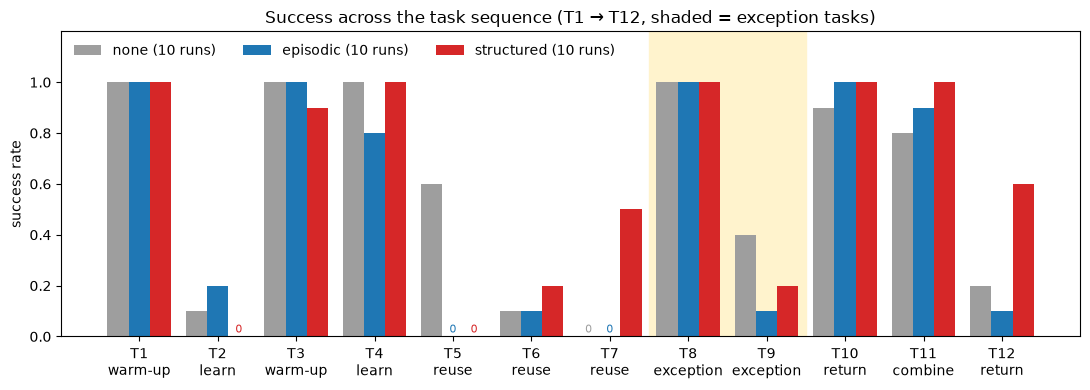

In [14]:
rates = df.pivot_table(index="task", columns="condition", values="correct", aggfunc="mean").reindex(ORDER)[list(CONDITIONS)]
n_runs = df.groupby("condition")["run"].nunique()
colors = {"none": "#9e9e9e", "episodic": "#1f77b4", "structured": "#d62728"}

fig, ax = plt.subplots(figsize=(11, 4))
width = 0.27
for i, c in enumerate(CONDITIONS):
    ax.bar([x + (i - 1) * width for x in range(len(ORDER))], rates[c], width,
           label=f"{c} ({n_runs[c]} runs)", color=colors[c])
    for x, v in enumerate(rates[c]):
        if v == 0:  # a zero-height bar is invisible: mark it
            ax.text(x + (i - 1) * width, 0.005, "0", ha="center", va="bottom", fontsize=8, color=colors[c])
for x, tid in enumerate(ORDER):
    if TASKS[tid]["type"] == "exception":
        ax.axvspan(x - 0.5, x + 0.5, color="#fff3cd", zorder=0)
ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels([f"{tid}\n{TASKS[tid]['type']}" for tid in ORDER])
ax.set_ylabel("success rate")
ax.set_ylim(0, 1.2)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_title("Success across the task sequence (T1 → T12, shaded = exception tasks)")
ax.legend(loc="upper left", ncol=3, frameon=False)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/success_by_task.png", dpi=200)
plt.show()

In [15]:
# Wrong answers by cause (grader labels; never shown to the agent or the memory)
wrong = df[~df["correct"]]
causes = pd.crosstab([wrong["task"], wrong["label"]], wrong["condition"]).reindex(columns=list(CONDITIONS), fill_value=0)
causes.loc[sorted(causes.index, key=lambda ix: (ORDER.index(ix[0]), ix[1]))]

condition                                                                                          none  \
task label                                                                                                
T2   Default projection EPSG:3857 (rule B). The yes/no part is still right.                           7   
     other                                                                                            2   
T3   other                                                                                            0   
T4   Counted every row with a population, including DC and Puerto Rico (rule A).                      0   
     other                                                                                            0   
T5   Default projection EPSG:3857 (rule B).                                                           4   
T6   Default projection EPSG:3857 (rule B).                                                           6   
     Right states, but areas from the default projection EPSG:3857 (rule B).                          1   
     other                                                                                            2   
T7   Default projection EPSG:3857 (rule B).                                                          10   
T9   Default planar distance in EPSG:3857.                                                            6   
T10  Included DC: rule A not applied, or the T8 exception carried over to a states-only question.     1   
T11  Default planar distance in EPSG:3857: distances inflated, states missed.                         2   
T12  Default projection EPSG:3857 for area (rule B not reapplied after T9).                           6   
     Used every row with a population, including DC and Puerto Rico (rule A).                         0   
     other                                                                                            2   

condition                                                                                          episodic  \
task label                                                                                                    
T2   Default projection EPSG:3857 (rule B). The yes/no part is still right.                               5   
     other                                                                                                3   
T3   other                                                                                                0   
T4   Counted every row with a population, including DC and Puerto Rico (rule A).                          1   
     other                                                                                                1   
T5   Default projection EPSG:3857 (rule B).                                                              10   
T6   Default projection EPSG:3857 (rule B).                                                               7   
     Right states, but areas from the default projection EPSG:3857 (rule B).                              1   
     other                                                                                                1   
T7   Default projection EPSG:3857 (rule B).                                                              10   
T9   Default planar distance in EPSG:3857.                                                                9   
T10  Included DC: rule A not applied, or the T8 exception carried over to a states-only question.         0   
T11  Default planar distance in EPSG:3857: distances inflated, states missed.                             1   
T12  Default projection EPSG:3857 for area (rule B not reapplied after T9).                               8   
     Used every row with a population, including DC and Puerto Rico (rule A).                             0   
     other                                                                                                1   

condition                                                                 

Did the stored projection rule matter? For the structured runs, a memory counts as holding the rule if one of its records recommends EPSG:5070; records that mention EPSG:5070 only to keep the EPSG:3857 default (run 7) do not count. The lines excluded that way are printed so the classification can be checked.

In [16]:
NEGATED = ("If unspecified, use EPSG:3857", "If none is requested, use the tool default", "use EPSG:3857 when",
           "do not mix EPSG:5070", "do not rank with EPSG:5070", "default EPSG:3857 unless", "defaulting to EPSG:3857")


def recommends_5070(memory_text):
    return any("5070" in line and not any(s in line for s in NEGATED) for line in memory_text.splitlines())


structured = [t for t in traces if t["condition"] == "structured"]
rule = pd.DataFrame([{"task": t["task"], "rule in memory": recommends_5070(t["memory_shown"]), "correct": t["correct"]}
                     for t in structured if t["task"] in ("T5", "T6", "T7", "T12")])
rule_counts = rule.groupby(["task", "rule in memory"])["correct"].agg(["sum", "count"])
rule_table = (rule_counts["sum"].astype(str) + "/" + rule_counts["count"].astype(str)).unstack(fill_value="0/0")
print(rule_table.reindex(["T5", "T6", "T7", "T12"]).rename(columns={True: "with the rule", False: "without"}), "\n")
print("Lines that mention EPSG:5070 but were not counted as recommending it:")
for line in sorted({l for t in structured for l in t["memory_shown"].splitlines()
                    if "5070" in l and any(s in l for s in NEGATED)}):
    print("  ", line[:160])

rule in memory without with the rule
task                                
T5                0/10           0/0
T6                 1/6           1/4
T7                 0/3           5/7
T12                0/1           6/9 

Lines that mention EPSG:5070 but were not counted as recommending it:
   - [m2 | warning] When: Comparing or reporting area or density Do: Use one projection consistently for retrieval, ranking, and reporting. If unspecified, use EPS
   - [m2 | warning] When: Comparing or reporting regions by area Do: Use the same projection for area ranking and reported values. If none is requested, use the to


## 11. Memory after each task (run 1 of each memory condition)

For episodic memory: which past episodes were shown before each task, and what was stored after it. For structured memory: the full memory after each update, with the writer's change log.

In [17]:
for condition in ("episodic", "structured"):
    print(f"\n########## {condition}, run 1 ##########")
    show_memory_timeline(traces, condition, 1)


########## episodic, run 1 ##########
T1 (right) | shown before this task: - | stored after: T1:right
T2 (WRONG) | shown before this task: ['T1'] | stored after: T1:right, T2:wrong
T3 (right) | shown before this task: ['T1', 'T2'] | stored after: T1:right, T2:wrong, T3:right
T4 (right) | shown before this task: ['T3', 'T1', 'T2'] | stored after: T1:right, T2:wrong, T3:right, T4:right
T5 (WRONG) | shown before this task: ['T4', 'T3', 'T1'] | stored after: T1:right, T2:wrong, T3:right, T4:right, T5:wrong
T6 (WRONG) | shown before this task: ['T2', 'T5', 'T4'] | stored after: T1:right, T2:wrong, T3:right, T4:right, T5:wrong, T6:wrong
T7 (WRONG) | shown before this task: ['T5', 'T4', 'T1'] | stored after: T1:right, T2:wrong, T3:right, T4:right, T5:wrong, T6:wrong, T7:wrong
T8 (right) | shown before this task: ['T1', 'T3', 'T4'] | stored after: T1:right, T2:wrong, T3:right, T4:right, T5:wrong, T6:wrong, T7:wrong, T8:right
T9 (WRONG) | shown before this task: ['T2', 'T5', 'T7'] | stored aft

## 12. Final structured memory (every run)

In [18]:
for run in sorted(df[df["condition"] == "structured"]["run"].unique()):
    last = sequence(traces, "structured", run)[-1]
    acc = sum(t["correct"] for t in sequence(traces, "structured", run))
    print(f"--- structured run {run} ({acc}/12 correct) ---")
    print(render_records(last["memory_after"]), "\n")

--- structured run 1 (7/12 correct) ---
- [m1 | procedure] When: State population or density thresholds/rankings Do: Use exact explicit 50-state names, excluding DC and territories. Filters are strict; use get_density with EPSG:5070, and rank or compare unrounded values. (evidence: T1:right, T5:wrong, T7:right, T12:wrong)
- [m2 | procedure] When: Population or area rankings Do: Confirm whether the request means states or all regions; obtain each ranking independently and compare names. Use EPSG:5070 for area. (evidence: T2:wrong, T6:wrong)
- [m7 | exception] When: U.S. headline population Do: Use 50 states plus DC, excluding territories; do not use get_population(all) total. (evidence: T8:right)
- [m8 | procedure] When: Unspecified geographic distance Do: Use distance method="geodesic"; default planar EPSG:3857 may be inappropriate. (evidence: T9:wrong, T11:right)
- [m9 | procedure] When: States within a centroid-distance threshold Do: Pass the 50 states to distance, use geodesic and t

## 13. Two trajectories

Candidates are found automatically; the two shown below are discussed in the next cell.

In [19]:
def find(condition, task, correct):
    return [t for t in traces if t["condition"] == condition and t["task"] == task and t["correct"] == correct]


print("Memory helped (higher success rate than no memory on the same task):")
for tid in ORDER:
    for c in ("episodic", "structured"):
        if rates.loc[tid, c] > rates.loc[tid, "none"]:
            print(f"  {tid} {c}: {rates.loc[tid, c]:.0%} vs none {rates.loc[tid, 'none']:.0%}; "
                  f"right in runs {[t['run'] for t in find(c, tid, True)]}")
print("\nMemory misled (memory wrong where no memory is mostly right, or a memory-induced label):")
INDUCED = ("Excluded DC", "Planar distance in EPSG:5070", "T8 exception carried over")
for t in traces:
    if t["condition"] != "none" and not t["correct"]:
        base_rate = rates.loc[t["task"], "none"]
        if base_rate >= 0.6 or any(s in (t["label"] or "") for s in INDUCED):
            print(f"  {t['task']} {t['condition']} run {t['run']}: {t['label']} (none: {base_rate:.0%} right)")

Memory helped (higher success rate than no memory on the same task):
  T2 episodic: 20% vs none 10%; right in runs [9, 10]
  T6 structured: 20% vs none 10%; right in runs [9, 10]
  T7 structured: 50% vs none 0%; right in runs [1, 5, 6, 8, 10]
  T10 episodic: 100% vs none 90%; right in runs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  T10 structured: 100% vs none 90%; right in runs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  T11 episodic: 90% vs none 80%; right in runs [1, 2, 3, 4, 5, 7, 8, 9, 10]
  T11 structured: 100% vs none 80%; right in runs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  T12 structured: 60% vs none 20%; right in runs [2, 4, 6, 7, 9, 10]

Memory misled (memory wrong where no memory is mostly right, or a memory-induced label):
  T5 episodic run 1: Default projection EPSG:3857 (rule B). (none: 60% right)
  T5 episodic run 2: Default projection EPSG:3857 (rule B). (none: 60% right)
  T4 episodic run 3: Counted every row with a population, including DC and Puerto Rico (rule A). (none: 100% right)
  T5 e

In [20]:
HELPED = ("structured", 1, "T7")
MISLED = ("structured", 2, "T5")
for condition, run, task in (HELPED, MISLED):
    show_trace(next(t for t in traces if (t["condition"], t["run"], t["task"]) == (condition, run, task)))

=== structured | run 1 | T7 | CORRECT ===
Memory shown to the agent:
  | MEMORY: lessons you recorded after earlier requests, based on whether a reviewer judged each answer CORRECT or INCORRECT. Apply a lesson only when its 'when' condition matches the current request.
  | - [m1 | procedure] When: Population extrema or threshold counts Do: Use get_population with exact names and strict greater_than/less_than filters; use order and limit for extrema. Explicitly restrict state requests to the 50 states, excluding DC and territories. (evidence: T1:right, T3:right, T4:right)
  | - [m2 | procedure] When: Comparing population rank with area rank Do: Independently obtain population and area leaders, verify whether the request means states or all areas, and compare their names explicitly. (evidence: T2:wrong)
  | - [m5 | warning] When: Ranking states by area-derived density Do: Likely use EPSG:5070 (equal-area) rather than EPSG:3857, explicitly pass the 50 state names, then rank the returned d

**Memory helped: structured, run 1, T7 (the 5 most densely populated states).** Without memory T7 failed in 10/10 runs, always reporting EPSG:3857 densities (the default projection in 7 runs, passed explicitly in 2; one run also queried EPSG:5070 but reported the default values). EPSG:3857 inflates area, so every density comes out about 40% too low (New Jersey 247 instead of 423 people/km²). In structured run 1 the lesson did not come from T2: after the T2 failure the writer blamed the choice of regions. It came from the next failure. After T5 (least dense, wrong) the writer added *m5: "Ranking states by area-derived density: likely use EPSG:5070 (equal-area) rather than the default EPSG:3857"*. At T7 the agent followed m5 directly, `get_density(<the 50 states>, projection="EPSG:5070", order="desc", limit=5)`, and was right; the writer then added T7:right as evidence. Over the 10 structured runs, T7 was right in 5/7 runs whose memory recommended EPSG:5070 and in 0/3 without such a rule, two of which held the opposite rule, "use EPSG:3857 when unspecified" (T12: 6/9 vs 0/1; see the table in section 10).

**Memory misled: structured, run 2, T5 (the 5 least densely populated states).** Without memory the agent answered T5 correctly, choosing EPSG:5070 unprompted, in 6/10 runs. In run 2 the T2 verdict was INCORRECT and the writer guessed the cause was inconsistent projections, storing *m2: "...use get_area with exact names and the same projection (default EPSG:3857 unless requested)"*. At T5 the agent carried m2 over to density and passed `projection="EPSG:3857"` explicitly, reporting Alaska at 0.08 instead of 0.43 people/km². The binary verdict said *that* T2 was wrong, not *why*, and the writer's diagnosis turned the actual error (the default projection) into a rule. Runs 7 and 10 stored the same "use the default EPSG:3857" rule after T2. Such a rule could also survive later failures: run 2 only rephrased it after T5 failed ("if none is specified, use the tool default") and replaced it after T6, and run 7 kept it through the T5 and T6 failures until T7. Both memory conditions went 0/10 on T5.

Episodic memory misled the same way through a lucky success. In episodic run 3, T4 retrieved the T3 episode (judged CORRECT), which used `get_population(names="all", greater_than=<Wisconsin>)`. The agent reused it with `less_than` and counted DC and Puerto Rico (31 instead of 29). T3's procedure was only right because DC and Puerto Rico have fewer people than Wisconsin.

## 14. Findings

- **Overall (10 runs per condition):** no memory 71/120 (59%), episodic 62/120 (52%), structured 74/120 (62%). Neither memory condition differs significantly from no memory overall (Fisher exact p = 0.30 and 0.79). Mean cost per run of 12 tasks: $0.0204, $0.0235 and $0.0408; the structured writer adds about 3,600 input and 750 output tokens per task. The whole experiment, including the smoke test, cost $0.86.
- **H1 is not supported as stated.** Structured memory did not fix the first reuse tasks (T5 0/10 and T6 2/10, against 6/10 and 1/10 without memory). It did improve the later ones, T7 (0/10 → 5/10, nominal p = 0.03) and T12 (2/10 → 6/10, p = 0.17), but not to the predicted 4/5. The predicted mechanism was wrong: in no run did the writer diagnose the projection after T2. A record recommending EPSG:5070 appeared only after one to three further area or density failures (one in runs 1, 5, 6 and 10; two in runs 2, 4, 8 and 9; three in run 7) and never in run 3. Episodic memory never learned the rule (T5–T7: 0/10, 1/10, 0/10): retrieval never showed the T2 episode at T5 or T7, and showing it at T6 (all 10 runs) did not help (1/10).
- **Memory hurt the first reuse task.** T5 fell from 6/10 without memory to 0/10 in both memory conditions (nominal p = 0.01 each). With structured memory the agent always started T5 with `list_regions` to scope the rows (10/10 runs, against 2/10 without memory; all 10 memories held a lesson about restricting to the 50 states) and passed EPSG:5070 in only 1 run.
- **H2 is partly supported.** Memory did not help on T9 (no memory 4/10, episodic 1/10, structured 2/10; not significant), but not through the predicted mechanism: every T9 failure in every condition used the default planar EPSG:3857, never planar EPSG:5070. T8 was 10/10 in every condition, so the 50-states lesson never removed DC. On T1, T3, T4 and T10 every condition stayed at 8/10 or better, while episodic memory added 13% input tokens per task on these four tasks (19% over all twelve).
- **Evidence of learning:** within structured runs, success on the later density and area tasks follows a failure that was written into memory, and depends on the rule being present (T7 5/7 with it, 0/3 without). The geodesic exception was learned from the T9 failure and reused: at T11 the structured memory said "use geodesic" in 10/10 runs, and T11 was right 10/10 (no memory 8/10).
- **Retrieved but not applied:** in structured run 1 the projection rule was stored for density only, and T6 (an area ranking) still used the default. In run 1 T12 the agent applied all the right rules (EPSG:5070, the 50 states, overall density 34.63) but counted the rows above the threshold by eye and got 18 instead of 16; the grader's automatic label blames rule A only because 18 matches that known mistake.
- **Caveats:** 10 runs per condition detect only large effects. The per-task p-values are nominal: after a Holm correction for the 24 per-task tests none is significant (T5 0.26, T7 0.72), and within a single batch of 5 runs only T5 in runs 1–5 reaches p < 0.05. The T5 drop and the T7 gain rest on the same direction appearing in both batches, so they are suggestive, not established. The no-memory baseline moved between Oct 6 and Oct 11 with identical prompts (T2 3/5 → 1/10, T5 0/5 → 6/10), so only the same-day, interleaved runs are compared. Grader labels for wrong answers are heuristic (see run 1 T12).
- **What to change in a second version:** binary feedback leaves the writer guessing the cause, so a one-line reviewer note or the expected value would make credit assignment possible. The writer should keep competing diagnoses marked uncertain until a later task confirms one, and should drop a rule as soon as a task that followed it fails (runs 2 and 7 kept "use the default" through later failures). Episodic retrieval matched only the wording of the new request against the stored episodes (request, calls and answer), and T5's request ("least densely populated") shares few words with the T2 episode, so T2 was never retrieved for T5. Embedding-based retrieval, or always showing the most recent INCORRECT episodes, would surface it.